# 17. D4 — 파생 변수 5종 이탈 크기 규칙 (학습 없음)
2단계 순위 = 날짜 안 이탈 크기 합. 입력은 파생 변수 5종 9개(입열량·동저항·I/F와 각각의 이동 중앙값 편차·직전 변화량)이고, 각 값의 |강건 z|를 날짜마다 계산해 더한다.
1단계 개수 = 고정 불량률(학습 날짜 평균 불량률 × 그날 타점 수). 정답도 개수도 순위에 쓰지 않으므로 Stellantis N.V.와 KAMP에 완전히 같은 규칙이다.
15·16 결과를 본 뒤 시험한 후보라 탐색 결과로 표시한다. 규칙은 1장 [표 3]의 정의("기준에서 벗어날수록 위험")를 그대로 옮긴 것이다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.metrics import roc_auc_score
import br
from br import spec as S, budget as B, plot as P
from wl.metrics import inclusion_prob, within_loc_auroc
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
Xp, pday, pcnt, py, _ = S.load_polito("derived5_absz")
rule_p = Xp.sum(axis=1).values
RAW = pd.read_pickle(br.RES / "same_model_scores.pkl")
raw_p = np.mean([g.sort_values("row").score.values for _, g in RAW[(RAW.data == "polito") & (RAW.model == "PVC MLP")].groupby("seed")], 0)
P0 = wldata.load_polito(); body, loc = P0.body.values, P0["loc"].values
rng = np.random.default_rng(8); ub = np.unique(body)
Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, body)]
ud, gi = np.unique(pday, return_inverse=True); n = np.bincount(gi); pos = np.bincount(gi, weights=py)
def ci(a): return f"{np.mean(a):+.3f} [{np.quantile(a,.025):+.3f}, {np.quantile(a,.975):+.3f}]"

## 1. Stellantis N.V. — D4 규칙의 검사 예산 성능 (숨긴 정답으로 채점)

In [2]:
rows = []
for b in (.05, .1, .2, .3):
    k = np.ceil(b * n - 1e-9); pr = (k / n)[gi]
    pd4, pr_raw = inclusion_prob(rule_p, k, gi), inclusion_prob(raw_p, k, gi)
    rows.append({"예산": f"{int(b*100)}%", "검사 수": int(k.sum()), "무작위": round((pr * py).sum(), 1), "D4 규칙": round((pd4 * py).sum(), 1),
                 "raw PVC": round((pr_raw * py).sum(), 1), "D4−무작위 포착률 [95%]": ci((Wb @ ((pd4 - pr) * py)) / (Wb @ py)),
                 "D4−raw [95%]": ci((Wb @ ((pd4 - pr_raw) * py)) / (Wb @ py))})
d4 = pd.DataFrame(rows); d4.to_csv(br.RES / "d4_rule_polito.csv", index=False, encoding="utf-8-sig"); display(d4)
grp = np.char.add(pday.astype(str), "_" + loc.astype(str))
print(f"AUROC D4 {roc_auc_score(py, rule_p):.3f}, raw {roc_auc_score(py, raw_p):.3f} | 같은 날·위치 안 AUROC D4 {within_loc_auroc(py, rule_p, grp):.3f}, raw {within_loc_auroc(py, raw_p, grp):.3f}")

,예산,검사 수,무작위,D4 규칙,raw PVC,D4−무작위 포착률 [95%],D4−raw [95%]
0,5%,109,4.9,10.0,8.0,"+0.063 [+0.017, +0.108]","+0.026 [-0.048, +0.106]"
1,10%,206,8.6,17.0,22.0,"+0.103 [+0.034, +0.159]","-0.060 [-0.141, +0.035]"
2,20%,403,16.0,28.0,37.0,"+0.150 [+0.059, +0.238]","-0.109 [-0.226, +0.017]"
3,30%,601,24.4,42.0,52.0,"+0.219 [+0.085, +0.331]","-0.124 [-0.269, +0.000]"


AUROC D4 0.656, raw 0.719 | 같은 날·위치 안 AUROC D4 0.515, raw 0.576


## 2. 위치 효과 점검과 두 순위의 결합
D4는 날짜 안 이탈이라 위치 수준 정보가 적고, raw PVC는 위치 수준 신호에 의존했다. 두 순위가 서로 다른 불량을 잡는지 본다.

In [3]:
k = np.ceil(.1 * n - 1e-9)
a_ = inclusion_prob(rule_p, k, gi); b_ = inclusion_prob(raw_p, k, gi)
print("10% 예산에서 D4만 잡은 불량(기대):", round(((a_ * (1 - b_)) * py).sum(), 1), " raw만:", round(((b_ * (1 - a_)) * py).sum(), 1), " 둘 다:", round((a_ * b_ * py).sum(), 1))
rk = lambda s: pd.Series(s).groupby(pday).rank(pct=True).values
comb = (rk(rule_p) + rk(raw_p)) / 2
rows = []
for b in (.05, .1, .2, .3):
    kk = np.ceil(b * n - 1e-9); pc = inclusion_prob(comb, kk, gi); pr_ = inclusion_prob(raw_p, kk, gi)
    rows.append({"예산": f"{int(b*100)}%", "raw PVC": round((pr_ * py).sum(), 1), "결합(순위 평균)": round((pc * py).sum(), 1),
                 "결합−raw [95%]": ci((Wb @ ((pc - pr_) * py)) / (Wb @ py))})
display(pd.DataFrame(rows))

10% 예산에서 D4만 잡은 불량(기대): 9.0  raw만: 14.0  둘 다: 8.0


,예산,raw PVC,결합(순위 평균),결합−raw [95%]
0,5%,8.0,18.5,"+0.131 [+0.028, +0.229]"
1,10%,22.0,24.0,"+0.025 [-0.056, +0.106]"
2,20%,37.0,38.0,"+0.015 [-0.068, +0.113]"
3,30%,52.0,50.0,"-0.026 [-0.078, +0.026]"


## 3. KAMP — 같은 규칙 적용

In [4]:
Xk, kday, kcnt, _, kblk = S.load_kamp("derived5_absz")
rule_k = Xk.sum(axis=1).values
fin = pd.read_csv(br.RES / "final_kamp_recommendations.csv")
raw_k = fin["위험점수"].values
ok = ~kblk
rows = []
for d in np.unique(kday):
    m = ok & (kday == d); kk = int(np.ceil(.1 * m.sum())); ix = np.flatnonzero(m)
    A = set(ix[np.argsort(-rule_k[m])[:kk]]); Bs = set(ix[np.argsort(-raw_k[m])[:kk]])
    rows.append({"date": d, "순위대상": int(m.sum()), "10% 검사 수": kk, "D4·raw 상위 10% 겹침": round(len(A & Bs) / kk, 3)})
display(pd.DataFrame(rows))
raw = pd.read_excel(wldata.KAMP_XLSX, sheet_name="Raw data")
cols = ["weld current(kA)", "weld Voltage(v)", "weld time(ms)", "weld force(bar)"]
top = np.zeros(len(kday), bool)
for d in np.unique(kday):
    m = ok & (kday == d); kk = int(np.ceil(.1 * m.sum())); ix = np.flatnonzero(m); top[ix[np.argsort(-rule_k[m])[:kk]]] = True
print("D4 상위 10% 타점 vs 나머지(블록 제외) 조건 평균과 표준편차")
display(pd.DataFrame({"D4 상위 10% 평균": raw.loc[top, cols].mean(), "나머지 평균": raw.loc[ok & ~top, cols].mean(),
                      "D4 상위 10% 표준편차": raw.loc[top, cols].std(), "나머지 표준편차": raw.loc[ok & ~top, cols].std()}).round(3))
pd.DataFrame({"idx": raw["idx"], "date": kday, "복사블록": kblk, "D4 이탈크기합": rule_k, "D4 상위10%": top}).to_csv(
    br.RES / "kamp_d4_rule_scores.csv", index=False, encoding="utf-8-sig")

,date,순위대상,10% 검사 수,D4·raw 상위 10% 겹침
0,2020-03-24,1200,120,0.208
1,2020-03-25,1061,107,0.159
2,2020-03-26,1000,100,0.280
3,2020-03-27,1357,136,0.191
4,2020-03-30,1470,147,0.095
5,2020-03-31,1509,151,0.152
6,2020-04-02,2000,200,0.340
7,2020-04-03,509,51,0.098
8,2020-04-07,669,67,0.164


D4 상위 10% 타점 vs 나머지(블록 제외) 조건 평균과 표준편차


,D4 상위 10% 평균,나머지 평균,D4 상위 10% 표준편차,나머지 표준편차
weld current(kA),14.691,14.698,0.124,0.084
weld Voltage(v),2.701,2.702,0.025,0.004
weld time(ms),71.657,71.733,0.894,0.596
weld force(bar),2.362,2.336,0.116,0.041


## 4. 그림

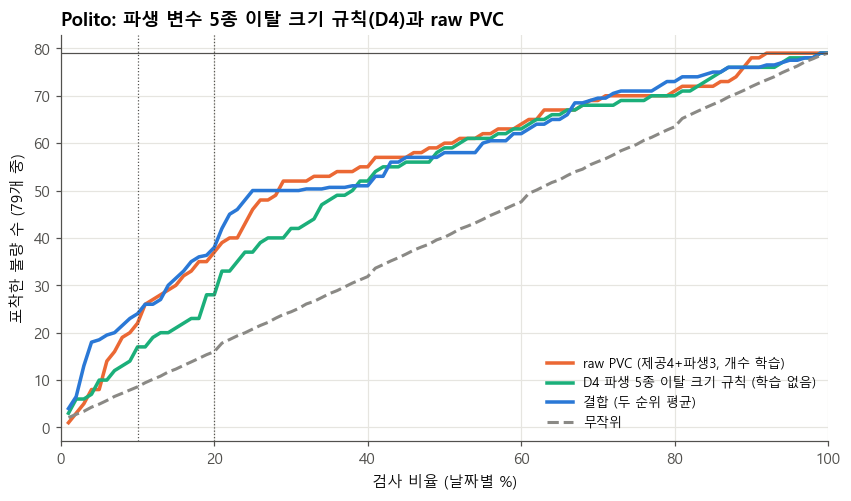

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
bb = B.BUDGETS
for nm, s_, col in [("raw PVC (제공4+파생3, 개수 학습)", raw_p, P.PAL[1]), ("D4 파생 5종 이탈 크기 규칙 (학습 없음)", rule_p, P.PAL[2]),
                    ("결합 (두 순위 평균)", comb, P.PAL[0])]:
    ax.plot(bb * 100, [(inclusion_prob(s_, np.ceil(b * n - 1e-9), gi) * py).sum() for b in bb], color=col, lw=2.3, label=nm)
ax.plot(bb * 100, [(np.ceil(b * n - 1e-9) / n * pos).sum() for b in bb], "--", color=P.GRAY, label="무작위")
for b in (10, 20): ax.axvline(b, color=P.INK2, lw=.8, ls=":")
ax.axhline(py.sum(), color=P.INK2, lw=.8)
ax.set_xlim(0, 100); ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel("포착한 불량 수 (79개 중)")
ax.set_title("Stellantis N.V.: 파생 변수 5종 이탈 크기 규칙(D4)과 raw PVC", loc="left", fontweight="bold"); ax.legend(fontsize=8.5, loc="lower right")
P.save(fig, "15_d4_rule"); plt.show()